# MLP — um passo na mão, classificação binária, multiclasse e profundidade

Notebook do exercício **MLP** (ANN-DL 2026.2). Contém, em ordem: a conferência
numérica do Exercício 1 (feito à mão no relatório), o MLP escrito do zero
(NumPy) com os tamanhos das camadas como argumento, e os Exercícios 2, 3 e 4.
As Figuras 1 a 6 são exibidas aqui e salvas em `../figures/`.

Regras: `rng = np.random.default_rng(42)` é o único gerador usado para
inicializar a rede; o scikit-learn entra só em `make_blobs`,
`make_classification`, `train_test_split`, `LogisticRegression` (linha de base)
e `confusion_matrix`.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

%matplotlib inline
np.set_printoptions(precision=6, suppress=True)

FIGURES = Path("..") / "figures"      # notebook em code/, figuras em ../figures
FIGURES.mkdir(exist_ok=True)

rng = np.random.default_rng(42)       # o MESMO rng em todo o relatório

## Exercício 1 — Um passo de retropropagação, na mão (conferência numérica)

A derivação completa está no relatório. Esta célula só refaz as contas com
NumPy para conferir cada número intermediário com 6 casas decimais.

In [2]:
x = np.array([0.5, -0.2]); y = 1.0
W1 = np.array([[0.3, -0.1], [0.2, 0.4]]); b1 = np.array([0.1, -0.2])
W2 = np.array([0.5, -0.3]); b2 = 0.2
eta = 0.3

# A — passagem direta
z1 = W1 @ x + b1
h1 = np.tanh(z1)
u2 = W2 @ h1 + b2
yhat = np.tanh(u2)
L = (y - yhat) ** 2
print(f"z1 = {z1}, h1 = {h1}")
print(f"u2 = {u2:.6f}, yhat = {yhat:.6f}, L = {L:.6f}")

# B — passagem reversa
dL_dyhat = -2 * (y - yhat)
dL_du2 = dL_dyhat * (1 - yhat ** 2)
dL_dW2 = dL_du2 * h1
dL_db2 = dL_du2
dL_dh1 = dL_du2 * W2
dL_dz1 = dL_dh1 * (1 - h1 ** 2)
dL_dW1 = np.outer(dL_dz1, x)
dL_db1 = dL_dz1
print(f"dL/dyhat = {dL_dyhat:.6f}, 1 - yhat^2 = {1 - yhat**2:.6f}, dL/du2 = {dL_du2:.6f}")
print(f"dL/dW2 = {dL_dW2}, dL/db2 = {dL_db2:.6f}")
print(f"dL/dh1 = {dL_dh1}, 1 - h1^2 = {1 - h1**2}, dL/dz1 = {dL_dz1}")
print(f"dL/dW1 =\n{dL_dW1}\ndL/db1 = {dL_db1}")

# C — atualização
W2_new = W2 - eta * dL_dW2; b2_new = b2 - eta * dL_db2
W1_new = W1 - eta * dL_dW1; b1_new = b1 - eta * dL_db1
print(f"W2' = {W2_new}, b2' = {b2_new:.6f}")
print(f"W1' =\n{W1_new}\nb1' = {b1_new}")

# segunda passagem direta com os parâmetros novos
h1n = np.tanh(W1_new @ x + b1_new)
yhat_n = np.tanh(W2_new @ h1n + b2_new)
print(f"segunda passagem: yhat = {yhat_n:.6f}, L = {(y - yhat_n) ** 2:.6f}  (antes: {L:.6f})")

z1 = [ 0.27 -0.18], h1 = [ 0.263625 -0.178081]
u2 = 0.385237, yhat = 0.367247, L = 0.400377
dL/dyhat = -1.265507, 1 - yhat^2 = 0.865130, dL/du2 = -1.094828
dL/dW2 = [-0.288624  0.194968], dL/db2 = -1.094828
dL/dh1 = [-0.547414  0.328448], 1 - h1^2 = [0.930502 0.968287], dL/dz1 = [-0.50937   0.318032]
dL/dW1 =
[[-0.254685  0.101874]
 [ 0.159016 -0.063606]]
dL/db1 = [-0.50937   0.318032]
W2' = [ 0.586587 -0.35849 ], b2' = 0.528448
W1' =
[[ 0.376405 -0.130562]
 [ 0.152295  0.419082]]
b1' = [ 0.252811 -0.29541 ]
segunda passagem: yhat = 0.711181, L = 0.083417  (antes: 0.400377)


## O MLP, escrito do zero

Uma única classe, usada **sem alteração** nos Exercícios 2, 3 e 4. Os tamanhos
das camadas são o argumento `layer_sizes` (ex.: `[2, 8, 1]` ou
`[4, 16, 16, 3]`); a saída (`"sigmoid"` + entropia cruzada binária ou
`"softmax"` + entropia cruzada categórica) e os hiperparâmetros são argumentos.

- **Passagem direta:** $\mathbf{h}^{(0)} = \mathbf{X}$; para cada camada,
  $\mathbf{u}^{(l)} = \mathbf{h}^{(l-1)}\mathbf{W}^{(l)} + \mathbf{b}^{(l)}$ e
  $\mathbf{h}^{(l)} = \tanh(\mathbf{u}^{(l)})$ nas ocultas; na saída, sigmoide ou softmax.
- **Perda:** BCE $= -\frac{1}{N}\sum[y\log p + (1-y)\log(1-p)]$ ou
  CCE $= -\frac{1}{N}\sum_n\sum_k y_{nk}\log p_{nk}$.
- **Passagem reversa:** nos dois casos $\partial L/\partial \mathbf{u}^{(L)} = (\mathbf{p} - \mathbf{y})/N$
  (derivado no relatório); depois, camada a camada,
  $\partial L/\partial \mathbf{W}^{(l)} = \mathbf{h}^{(l-1)\top}\boldsymbol{\delta}^{(l)}$,
  $\partial L/\partial \mathbf{b}^{(l)} = \sum_n \boldsymbol{\delta}^{(l)}$ e
  $\boldsymbol{\delta}^{(l-1)} = (\boldsymbol{\delta}^{(l)}\mathbf{W}^{(l)\top}) \odot (1 - \mathbf{h}^{(l-1)2})$.
- **Atualização:** gradiente descendente em lote completo, $\theta \leftarrow \theta - \eta\,\partial L/\partial\theta$.

In [3]:
def tanh(u):
    return np.tanh(u)


def dtanh_from_h(h):
    '''Derivada da tanh escrita em função da própria ativação: 1 - tanh(u)^2.'''
    return 1.0 - h ** 2


def sigmoid(u):
    return 1.0 / (1.0 + np.exp(-u))


def softmax(u):
    e = np.exp(u - u.max(axis=1, keepdims=True))   # estável numericamente
    return e / e.sum(axis=1, keepdims=True)


class MLP:
    '''MLP com tanh nas camadas ocultas e sigmoide/softmax na saída.

    layer_sizes: lista [n_in, n_h1, ..., n_out]  -> qualquer profundidade.
    output:      "sigmoid" (BCE, n_out = 1) ou "softmax" (CCE, n_out = K).
    '''

    def __init__(self, layer_sizes, output="sigmoid", lr=0.1, rng=None):
        self.sizes = list(layer_sizes)
        self.output = output
        self.lr = lr
        # Inicialização: W ~ N(0, 1/n_in) (mantém a escala das pré-ativações), b = 0.
        self.W = [rng.normal(0.0, 1.0 / np.sqrt(n_in), size=(n_in, n_out))
                  for n_in, n_out in zip(self.sizes[:-1], self.sizes[1:])]
        self.b = [np.zeros(n_out) for n_out in self.sizes[1:]]

    def n_params(self):
        return int(sum(W.size + b.size for W, b in zip(self.W, self.b)))

    # ---------------------------------------------------------- passagem direta
    def forward(self, X):
        '''Guarda as ativações de cada camada (h[0] = X) para a passagem reversa.'''
        self.h = [X]
        a = X
        n_layers = len(self.W)
        for l, (W, b) in enumerate(zip(self.W, self.b)):
            u = a @ W + b                                   # pré-ativação
            if l < n_layers - 1:
                a = tanh(u)                                 # camada oculta
            else:
                a = sigmoid(u) if self.output == "sigmoid" else softmax(u)
            self.h.append(a)
        return a

    # ------------------------------------------------------------------- perda
    def loss(self, P, Y):
        eps = 1e-12
        if self.output == "sigmoid":
            return float(-np.mean(Y * np.log(P + eps) + (1 - Y) * np.log(1 - P + eps)))
        return float(-np.mean(np.sum(Y * np.log(P + eps), axis=1)))

    # --------------------------------------------------------- passagem reversa
    def backward(self, Y):
        '''Gradientes de todas as camadas, derivados à mão (sem autodiff).'''
        N = Y.shape[0]
        # dL/du na saída: (p - y)/N, tanto para sigmoide+BCE quanto softmax+CCE.
        delta = (self.h[-1] - Y) / N
        self.dW = [None] * len(self.W)
        self.db = [None] * len(self.b)
        for l in reversed(range(len(self.W))):
            self.dW[l] = self.h[l].T @ delta                # dL/dW^(l) = h^(l-1)^T delta
            self.db[l] = delta.sum(axis=0)                  # dL/db^(l) = soma sobre as amostras
            if l > 0:                                       # propaga para a camada anterior
                delta = (delta @ self.W[l].T) * dtanh_from_h(self.h[l])

    # ------------------------------------------------------------- atualização
    def update(self):
        for l in range(len(self.W)):
            self.W[l] -= self.lr * self.dW[l]
            self.b[l] -= self.lr * self.db[l]

    # ------------------------------------------------------------------ treino
    def fit(self, X, Y, epochs):
        '''Gradiente descendente em lote completo; devolve a perda por época.'''
        history = []
        for _ in range(epochs):
            P = self.forward(X)
            history.append(self.loss(P, Y))
            self.backward(Y)
            self.update()
        return history

    def predict(self, X):
        P = self.forward(X)
        if self.output == "sigmoid":
            return (P[:, 0] >= 0.5).astype(int)
        return P.argmax(axis=1)


def accuracy(model, X, y):
    return float(np.mean(model.predict(X) == y))

## Exercício 2 — Classificação binária que uma reta não resolve

### A — Gere os dados

treino: (800, 2), teste: (200, 2); classe 1 no treino = 0.500, no teste = 0.500


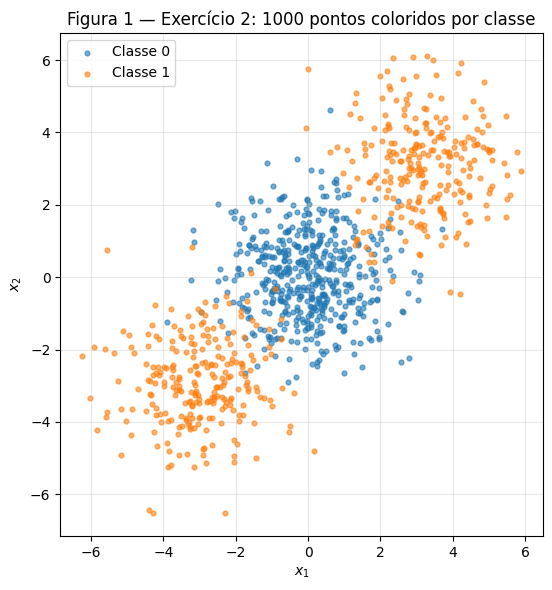

In [4]:
centers = np.array([[0., 0.], [3., 3.], [-3., -3.]])
X, c = make_blobs(n_samples=[500, 250, 250], centers=centers,
                  cluster_std=1.2, random_state=42)
y = (c > 0).astype(int)      # classe 0: 1 grupo | classe 1: 2 grupos

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"treino: {X_tr.shape}, teste: {X_te.shape}; classe 1 no treino = {y_tr.mean():.3f}, no teste = {y_te.mean():.3f}")

# Figura 1
fig, ax = plt.subplots(figsize=(7, 6))
for k, col in [(0, "tab:blue"), (1, "tab:orange")]:
    ax.scatter(X[y == k, 0], X[y == k, 1], s=12, alpha=0.6, color=col, label=f"Classe {k}")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_title("Figura 1 — Exercício 2: 1000 pontos coloridos por classe")
ax.legend(); ax.grid(alpha=0.3); ax.set_aspect("equal")
fig.tight_layout(); fig.savefig(FIGURES / "fig1.png", dpi=150); plt.show()

### B — Estabeleça a linha de base

Uma única fronteira linear (regressão logística do scikit-learn), ajustada no
treino e avaliada no teste. É a linha de base, não o modelo.

In [5]:
baseline2 = LogisticRegression().fit(X_tr, y_tr)
acc_base2 = baseline2.score(X_te, y_te)
print(f"linha de base linear — acurácia no teste = {acc_base2:.4f} ({acc_base2 * 100:.2f}%)")
print(f"coeficientes w = {baseline2.coef_[0]}, b = {baseline2.intercept_[0]:.4f}")

linha de base linear — acurácia no teste = 0.4750 (47.50%)
coeficientes w = [0.029633 0.001476], b = -0.0031


### C — Implemente o MLP

Arquitetura `[2, 8, 1]`: 2 entradas, 1 camada oculta de 8 neurônios `tanh`,
1 saída sigmoide; perda BCE; $\eta = 0.3$; 2000 épocas de lote completo.

arquitetura [2, 8, 1] (33 parâmetros), lr = 0.3, épocas = 2000
perda final de treino = 0.1062; acurácia treino = 0.9650; acurácia TESTE = 0.9150 (91.50%)


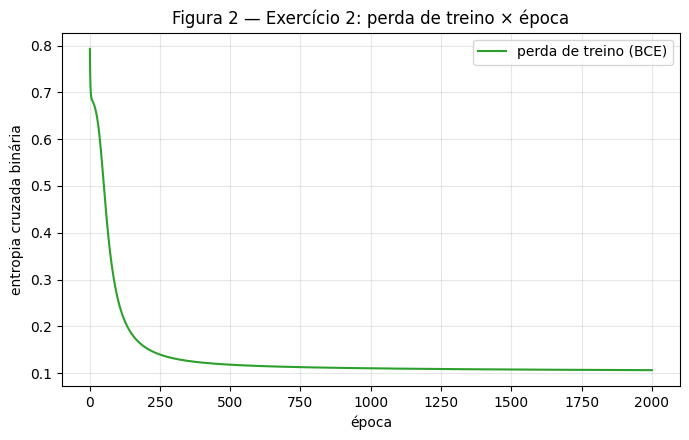

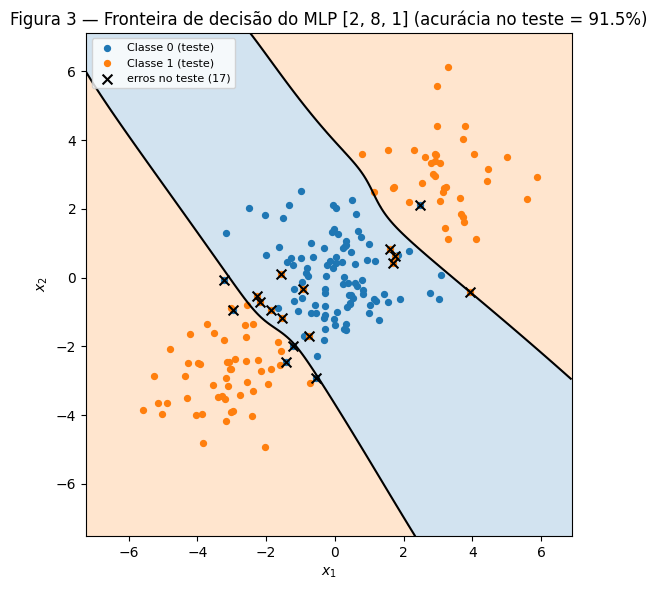

In [6]:
ARCH2, LR2, EPOCHS2 = [2, 8, 1], 0.3, 2000
mlp2 = MLP(ARCH2, output="sigmoid", lr=LR2, rng=rng)
hist2 = mlp2.fit(X_tr, y_tr[:, None], EPOCHS2)
acc2_tr, acc2_te = accuracy(mlp2, X_tr, y_tr), accuracy(mlp2, X_te, y_te)
print(f"arquitetura {ARCH2} ({mlp2.n_params()} parâmetros), lr = {LR2}, épocas = {EPOCHS2}")
print(f"perda final de treino = {hist2[-1]:.4f}; acurácia treino = {acc2_tr:.4f}; acurácia TESTE = {acc2_te:.4f} ({acc2_te * 100:.2f}%)")

# Figura 2
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(np.arange(1, EPOCHS2 + 1), hist2, color="tab:green", label="perda de treino (BCE)")
ax.set_xlabel("época"); ax.set_ylabel("entropia cruzada binária")
ax.set_title("Figura 2 — Exercício 2: perda de treino × época")
ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); fig.savefig(FIGURES / "fig2.png", dpi=150); plt.show()

# Figura 3 — fronteira de decisão em uma grade, pontos de TESTE por cima
pad = 1.0
xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, 400),
                     np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, 400))
grid = np.c_[xx.ravel(), yy.ravel()]
P_grid = mlp2.forward(grid)[:, 0].reshape(xx.shape)
fig, ax = plt.subplots(figsize=(7, 6))
ax.contourf(xx, yy, P_grid >= 0.5, levels=[-0.5, 0.5, 1.5], colors=["tab:blue", "tab:orange"], alpha=0.2)
ax.contour(xx, yy, P_grid, levels=[0.5], colors="black", linewidths=1.5)
pred_te = mlp2.predict(X_te)
for k, col in [(0, "tab:blue"), (1, "tab:orange")]:
    ax.scatter(X_te[y_te == k, 0], X_te[y_te == k, 1], s=18, color=col, label=f"Classe {k} (teste)")
wrong = pred_te != y_te
ax.scatter(X_te[wrong, 0], X_te[wrong, 1], marker="x", s=50, color="black",
           label=f"erros no teste ({wrong.sum()})")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_title(f"Figura 3 — Fronteira de decisão do MLP {ARCH2} (acurácia no teste = {acc2_te * 100:.1f}%)")
ax.legend(loc="upper left", fontsize=8); ax.set_aspect("equal")
fig.tight_layout(); fig.savefig(FIGURES / "fig3.png", dpi=150); plt.show()

## Exercício 3 — Multiclasse, a mesma rede

### A — Gere os dados

As 4 features são padronizadas (média e desvio **do treino**, em NumPy) antes
de entrar na rede; a linha de base recebe os mesmos dados padronizados.

In [7]:
X3, y3 = make_classification(n_samples=1500, n_features=4, n_informative=4,
                             n_redundant=0, n_repeated=0, n_classes=3,
                             n_clusters_per_class=2, class_sep=1.0,
                             random_state=42)
X3_tr, X3_te, y3_tr, y3_te = train_test_split(X3, y3, test_size=0.2, random_state=42, stratify=y3)

mu, sd = X3_tr.mean(axis=0), X3_tr.std(axis=0)       # estatísticas só do treino
X3_tr_s, X3_te_s = (X3_tr - mu) / sd, (X3_te - mu) / sd
Y3_tr = np.eye(3)[y3_tr]                               # one-hot para a CCE
print(f"treino: {X3_tr.shape}, teste: {X3_te.shape}; classes no teste: {np.bincount(y3_te)}")

treino: (1200, 4), teste: (300, 4); classes no teste: [100 100 100]


### B — Adapte a rede

Mesma classe `MLP`, mesmo `forward`, `backward` e `update`. O que muda são
argumentos: `layer_sizes=[4, 16, 3]` e `output="softmax"` (que seleciona a
softmax na saída e a entropia cruzada categórica em `loss`). A derivação de
$\partial L/\partial \mathbf{u}$ para softmax + CCE está no relatório.

In [8]:
baseline3 = LogisticRegression(max_iter=1000).fit(X3_tr_s, y3_tr)
acc_base3 = baseline3.score(X3_te_s, y3_te)
print(f"linha de base (regressão logística multinomial) — acurácia no teste = {acc_base3:.4f} ({acc_base3 * 100:.2f}%)")

ARCH3, LR3, EPOCHS3 = [4, 16, 3], 0.3, 2000
mlp3 = MLP(ARCH3, output="softmax", lr=LR3, rng=rng)
hist3 = mlp3.fit(X3_tr_s, Y3_tr, EPOCHS3)
acc3_tr, acc3_te = accuracy(mlp3, X3_tr_s, y3_tr), accuracy(mlp3, X3_te_s, y3_te)
print(f"arquitetura {ARCH3} ({mlp3.n_params()} parâmetros), lr = {LR3}, épocas = {EPOCHS3}")
print(f"perda final de treino = {hist3[-1]:.4f}; acurácia treino = {acc3_tr:.4f}; acurácia TESTE = {acc3_te:.4f} ({acc3_te * 100:.2f}%)")

linha de base (regressão logística multinomial) — acurácia no teste = 0.6633 (66.33%)


arquitetura [4, 16, 3] (131 parâmetros), lr = 0.3, épocas = 2000
perda final de treino = 0.3084; acurácia treino = 0.8792; acurácia TESTE = 0.8567 (85.67%)


### C — Treine e avalie

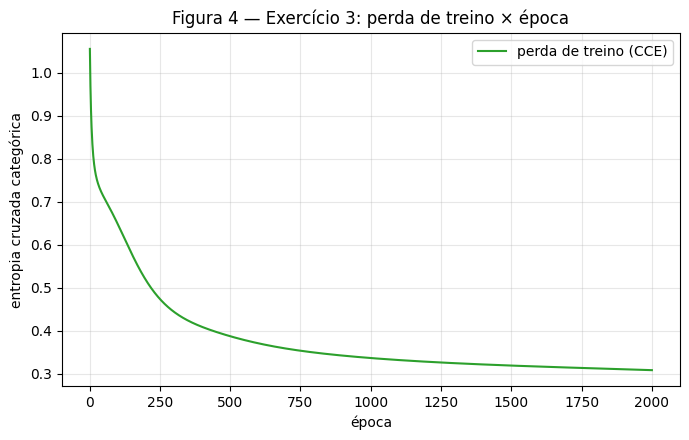

matriz de confusão (linhas = verdadeiro, colunas = predito):
 [[91  3  6]
 [12 76 12]
 [ 4  6 90]]
erros por par (soma das duas direções): {(0, 1): 15, (0, 2): 10, (1, 2): 18}
par mais confundido: classes (1, 2) com 18 erros
acurácia por classe: {0: 0.91, 1: 0.76, 2: 0.9}


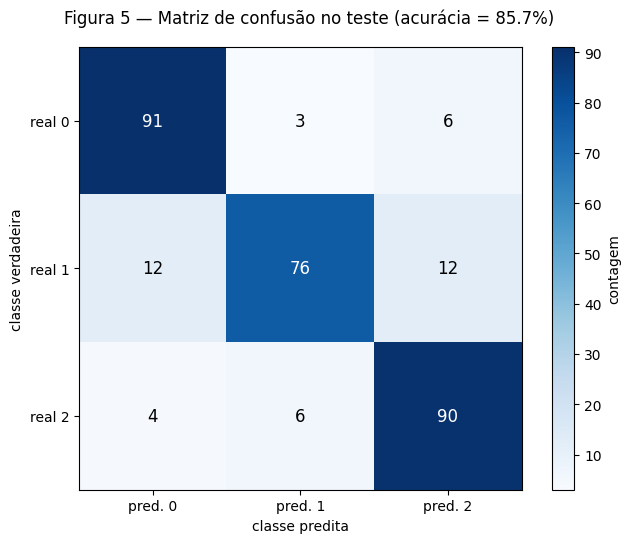

In [9]:
# Figura 4
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(np.arange(1, EPOCHS3 + 1), hist3, color="tab:green", label="perda de treino (CCE)")
ax.set_xlabel("época"); ax.set_ylabel("entropia cruzada categórica")
ax.set_title("Figura 4 — Exercício 3: perda de treino × época")
ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); fig.savefig(FIGURES / "fig4.png", dpi=150); plt.show()

# Figura 5 — matriz de confusão no teste
pred3 = mlp3.predict(X3_te_s)
cm = confusion_matrix(y3_te, pred3, labels=[0, 1, 2])
print("matriz de confusão (linhas = verdadeiro, colunas = predito):\n", cm)
off = cm.copy(); np.fill_diagonal(off, 0)
pairs = {(i, j): int(off[i, j] + off[j, i]) for i in range(3) for j in range(i + 1, 3)}
print("erros por par (soma das duas direções):", pairs)
worst = max(pairs, key=pairs.get)
print(f"par mais confundido: classes {worst} com {pairs[worst]} erros")
print("acurácia por classe:", {k: round(cm[k, k] / cm[k].sum(), 3) for k in range(3)})

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(cm, cmap="Blues")
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=12)
ax.set_xticks(range(3)); ax.set_yticks(range(3))
ax.set_xticklabels([f"pred. {k}" for k in range(3)]); ax.set_yticklabels([f"real {k}" for k in range(3)])
ax.set_xlabel("classe predita"); ax.set_ylabel("classe verdadeira")
fig.suptitle(f"Figura 5 — Matriz de confusão no teste (acurácia = {acc3_te * 100:.1f}%)")
fig.colorbar(im, ax=ax, label="contagem")
fig.tight_layout(); fig.savefig(FIGURES / "fig5.png", dpi=150); plt.show()

### D — Análise (apoio numérico)

Onde os 6 grupos (3 classes × 2 grupos) estão no espaço de 4 dimensões. O
gerador não devolve o rótulo de grupo, então os 2 centros de cada classe são
estimados com um k-means de 2 centros escrito em NumPy, sobre o treino
padronizado; em seguida mede-se a distância entre centros de classes diferentes.

In [10]:
def kmeans2(P, rng, iters=50):
    '''k-means com k = 2 em NumPy (só para localizar os 2 grupos de cada classe).'''
    C = P[rng.choice(len(P), 2, replace=False)]
    for _ in range(iters):
        lab = np.argmin(((P[:, None, :] - C[None]) ** 2).sum(axis=2), axis=1)
        C = np.array([P[lab == k].mean(axis=0) for k in range(2)])
    return C

centers3 = {k: kmeans2(X3_tr_s[y3_tr == k], rng) for k in range(3)}
for k, C in centers3.items():
    print(f"classe {k}: centros dos grupos (espaço padronizado) =\n{C}")
print("\ndistância mínima entre um grupo da classe i e um grupo da classe j:")
for i in range(3):
    for j in range(i + 1, 3):
        d = np.linalg.norm(centers3[i][:, None, :] - centers3[j][None, :, :], axis=2)
        print(f"  classes ({i}, {j}): min = {d.min():.3f}, média = {d.mean():.3f}")

classe 0: centros dos grupos (espaço padronizado) =
[[ 0.955337 -0.851358  0.741798  0.733579]
 [-0.237565 -1.021842 -0.651614 -0.590614]]
classe 1: centros dos grupos (espaço padronizado) =
[[-0.490936  0.359321  0.668768  0.465204]
 [-0.363035  0.634498 -0.984132 -0.763519]]
classe 2: centros dos grupos (espaço padronizado) =
[[-0.746202  0.700199 -0.683362  0.803421]
 [ 0.807535  0.325455  0.449471 -0.5983  ]]

distância mínima entre um grupo da classe i e um grupo da classe j:
  classes (0, 1): min = 1.703, média = 2.209
  classes (0, 2): min = 1.807, média = 2.205
  classes (1, 2): min = 1.457, média = 1.669


## Exercício 4 — Uma segunda camada oculta ajuda?

### A — Treine a rede mais profunda

Mesmos dados, mesma padronização, mesma taxa ($\eta = 0.3$), mesmo orçamento
(2000 épocas). Única mudança: `layer_sizes=[4, 16, 16, 3]`.

In [11]:
ARCH4 = [4, 16, 16, 3]
mlp4 = MLP(ARCH4, output="softmax", lr=LR3, rng=rng)
hist4 = mlp4.fit(X3_tr_s, Y3_tr, EPOCHS3)
acc4_tr, acc4_te = accuracy(mlp4, X3_tr_s, y3_tr), accuracy(mlp4, X3_te_s, y3_te)
print(f"arquitetura {ARCH4} ({mlp4.n_params()} parâmetros), lr = {LR3}, épocas = {EPOCHS3}")
print(f"perda final de treino = {hist4[-1]:.4f}; acurácia treino = {acc4_tr:.4f}; acurácia TESTE = {acc4_te:.4f} ({acc4_te * 100:.2f}%)")

arquitetura [4, 16, 16, 3] (403 parâmetros), lr = 0.3, épocas = 2000
perda final de treino = 0.2118; acurácia treino = 0.9283; acurácia TESTE = 0.8433 (84.33%)


### B — Compare

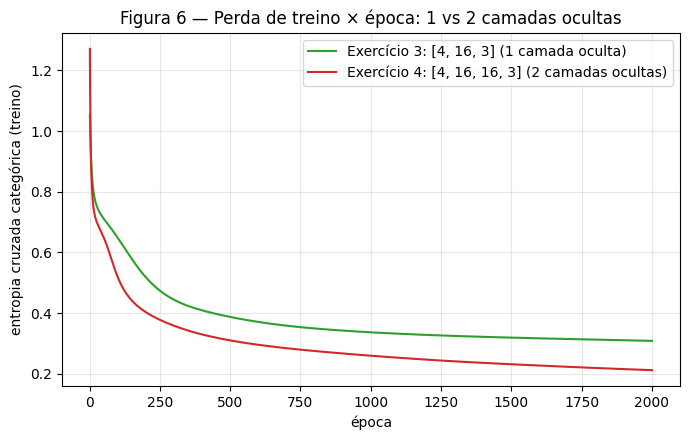

| | camadas ocultas | parâmetros | perda final de treino | acurácia no teste |
| Exercício 3 | 1 | 131 | 0.3084 | 85.67% |
| Exercício 4 | 2 | 403 | 0.2118 | 84.33% |


semente 42: Ex3 perda 0.2971 acc 85.33% | Ex4 perda 0.2156 acc 84.33%


semente 7: Ex3 perda 0.2776 acc 84.67% | Ex4 perda 0.2070 acc 86.67%


semente 123: Ex3 perda 0.2773 acc 84.33% | Ex4 perda 0.2145 acc 84.33%

média Ex3: perda 0.2840, acurácia 84.78% (± 0.42)
média Ex4: perda 0.2123, acurácia 85.11% (± 1.10)
diferença Ex4 - Ex3 (média das 3 sementes): +0.33 pontos percentuais


In [12]:
# Figura 6 — as duas curvas de perda nos mesmos eixos
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(np.arange(1, EPOCHS3 + 1), hist3, color="tab:green", label=f"Exercício 3: {ARCH3} (1 camada oculta)")
ax.plot(np.arange(1, EPOCHS3 + 1), hist4, color="tab:red", label=f"Exercício 4: {ARCH4} (2 camadas ocultas)")
ax.set_xlabel("época"); ax.set_ylabel("entropia cruzada categórica (treino)")
ax.set_title("Figura 6 — Perda de treino × época: 1 vs 2 camadas ocultas")
ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); fig.savefig(FIGURES / "fig6.png", dpi=150); plt.show()

print("| | camadas ocultas | parâmetros | perda final de treino | acurácia no teste |")
print(f"| Exercício 3 | 1 | {mlp3.n_params()} | {hist3[-1]:.4f} | {acc3_te * 100:.2f}% |")
print(f"| Exercício 4 | 2 | {mlp4.n_params()} | {hist4[-1]:.4f} | {acc4_te * 100:.2f}% |")

# Três sementes de inicialização para cada arquitetura (dados e split fixos)
SEEDS = [42, 7, 123]
rows = []
for seed in SEEDS:
    r = np.random.default_rng(seed)
    m3 = MLP(ARCH3, output="softmax", lr=LR3, rng=r); h3 = m3.fit(X3_tr_s, Y3_tr, EPOCHS3)
    r = np.random.default_rng(seed)
    m4 = MLP(ARCH4, output="softmax", lr=LR3, rng=r); h4 = m4.fit(X3_tr_s, Y3_tr, EPOCHS3)
    rows.append((seed, h3[-1], accuracy(m3, X3_te_s, y3_te), h4[-1], accuracy(m4, X3_te_s, y3_te)))
    print(f"semente {seed}: Ex3 perda {h3[-1]:.4f} acc {rows[-1][2] * 100:.2f}% | Ex4 perda {h4[-1]:.4f} acc {rows[-1][4] * 100:.2f}%")
R = np.array(rows)
print(f"\nmédia Ex3: perda {R[:, 1].mean():.4f}, acurácia {R[:, 2].mean() * 100:.2f}% (± {R[:, 2].std() * 100:.2f})")
print(f"média Ex4: perda {R[:, 3].mean():.4f}, acurácia {R[:, 4].mean() * 100:.2f}% (± {R[:, 4].std() * 100:.2f})")
print(f"diferença Ex4 - Ex3 (média das {len(SEEDS)} sementes): {(R[:, 4] - R[:, 2]).mean() * 100:+.2f} pontos percentuais")